In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [34]:
csv_path = "ETH-USD.csv"
df = pd.read_csv(csv_path)
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,308.644989,329.451996,307.056000,320.884003,320.884003,893249984
1,2017-11-10,320.670990,324.717987,294.541992,299.252991,299.252991,885985984
2,2017-11-11,298.585999,319.453003,298.191986,314.681000,314.681000,842300992
3,2017-11-12,314.690002,319.153015,298.513000,307.907990,307.907990,1613479936
4,2017-11-13,307.024994,328.415009,307.024994,316.716003,316.716003,1041889984


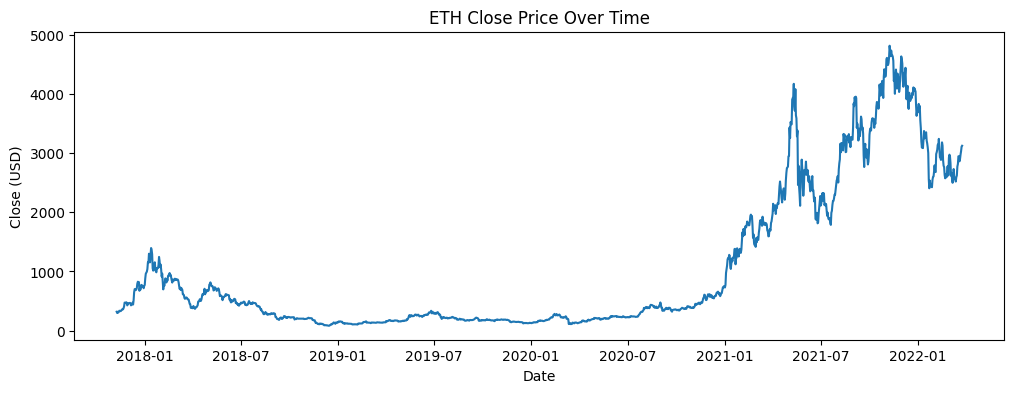

In [35]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Keep the target series (Close)
series = df[["Date", "Close"]].dropna()

plt.figure(figsize=(12,4))
plt.plot(series["Date"], series["Close"])
plt.title("ETH Close Price Over Time")
plt.xlabel("Date")
plt.ylabel("Close (USD)")
plt.show()

In [36]:
close_values = series["Close"].values.reshape(-1, 1)

n = len(close_values)
train_end = int(n * 0.80)
val_end   = int(n * 0.85)

train_raw = close_values[:train_end]
val_raw   = close_values[train_end:val_end]
test_raw  = close_values[val_end:]

scaler = MinMaxScaler()
train = scaler.fit_transform(train_raw)
val   = scaler.transform(val_raw)
test  = scaler.transform(test_raw)

train.shape, val.shape, test.shape


((1278, 1), (80, 1), (240, 1))

In [37]:
WINDOW = 30  # you can try 14, 30, 60

def make_windows(data, window=30):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])   # previous window days
        y.append(data[i])            # next day
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train, WINDOW)
X_val,   y_val   = make_windows(val, WINDOW)
X_test,  y_test  = make_windows(test, WINDOW)

X_train.shape, y_train.shape


((1248, 30, 1), (1248, 1))

In [38]:
tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0109 - mae: 0.0603 - val_loss: 0.0037 - val_mae: 0.0506
Epoch 2/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 8.3000e-04 - mae: 0.0163 - val_loss: 0.0039 - val_mae: 0.0526
Epoch 3/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 6.1241e-04 - mae: 0.0139 - val_loss: 0.0075 - val_mae: 0.0713
Epoch 4/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5.6199e-04 - mae: 0.0151 - val_loss: 0.0032 - val_mae: 0.0499
Epoch 5/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 5.4773e-04 - mae: 0.0145 - val_loss: 0.0025 - val_mae: 0.0439
Epoch 6/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 4.4739e-04 - mae: 0.0121 - val_loss: 0.0055 - val_mae: 0.0612
Epoch 7/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.9573e-04 - mae: 0.0129 - val_loss: 0.0024 - val_mae: 0.0433
Epoch 8/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 4.3807e-04 - mae: 0.0115 - val_loss: 0.0026 - val_mae: 0.0450
Epoch 9/25
39/39 ━━━━━━━━━━━━━━━━━━━

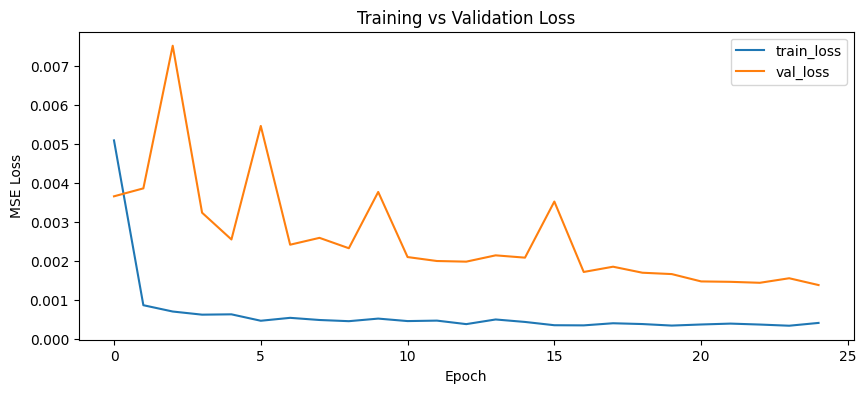

In [40]:
plt.figure(figsize=(10,4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [41]:
pred_test = model.predict(X_test)

# Inverse transform back to real USD prices
y_test_usd = scaler.inverse_transform(y_test)
pred_usd   = scaler.inverse_transform(pred_test)

mae = mean_absolute_error(y_test_usd, pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))

print(f"Test MAE:  {mae:.2f} USD")
print(f"Test RMSE: {rmse:.2f} USD")


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
Test MAE:  158.71 USD
Test RMSE: 207.20 USD


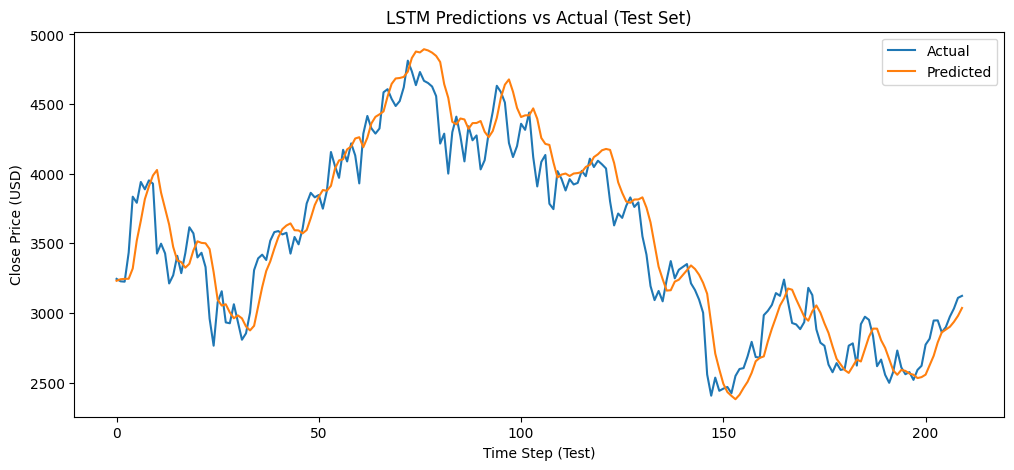

In [42]:
plt.figure(figsize=(12,5))
plt.plot(y_test_usd, label="Actual")
plt.plot(pred_usd, label="Predicted")
plt.title("LSTM Predictions vs Actual (Test Set)")
plt.xlabel("Time Step (Test)")
plt.ylabel("Close Price (USD)")
plt.legend()
plt.show()
